# NYC Yellow Taxi Trip Data Pipeline and Fare Prediction

**Student Name:** Bulusu Venkata Rama Kartikeya  

**Student Number:** s224938042  

**Email:** s224938042@deakin.edu.au

**Unit:** SIT731  

**Task:** Task 8HD – NYC TLC Pipeline Building 
 
**Implementation Pathway:** Pathway A – pandas-based workflow  

## Introduction and Problem Definition

This report presents an end-to-end data wrangling and modelling pipeline using the official New York City Taxi and Limousine Commission Yellow Taxi trip record data. The aim of the project is to demonstrate how raw monthly trip files can be converted into an analysis-ready dataset and then used to build a predictive model. The focus is not only on model accuracy, but also on the quality of the full data science workflow, including data inspection, validation, cleaning, feature engineering, evaluation, and interpretation.

For this analysis, the selected prediction problem is to estimate the total fare amount of a completed yellow taxi trip, given trip distance, trip duration, time, passenger, payment, and location-related features. This is framed as a post-hoc fare reconstruction problem rather than a pre-trip fare forecast, because some predictors (such as trip duration and average speed) are only known after the trip ends. This framing is meaningful for auditing fare consistency, identifying anomalous fares, and understanding which trip characteristics drive the final amount charged.This is a meaningful prediction task because fare amount is influenced by operational factors such as trip distance, trip duration, pickup time, congestion, passenger behaviour, and pickup/drop-off zones. Understanding these relationships can support transport analytics, taxi demand studies, fare behaviour analysis, and operational planning.

This notebook follows **Pathway A**, a pandas-based workflow. Three months of Yellow Taxi data from July, August, and September 2025 are used. This scope is suitable for a single-machine workflow because it provides enough records to support meaningful validation, feature engineering, and modelling, while remaining manageable in memory after filtering and sampling. The taxi zone lookup table is also used to add location metadata for pickup and drop-off zones.

## Importing Required Libraries

The following libraries are used for data loading, wrangling, visualisation, feature engineering, and predictive modelling. The workflow mainly uses pandas because this submission follows Pathway A. Scikit-learn is used for building baseline and stronger predictive models.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

## Data Acquisition and Scope

The raw data used in this project consists of three official NYC TLC Yellow Taxi monthly trip record files in Parquet format:

- Yellow Taxi trip data for July 2025

- Yellow Taxi trip data for August 2025

- Yellow Taxi trip data for September 2025

A taxi zone lookup CSV file is also used to attach human-readable pickup and drop-off zone information. The selected three-month period provides a realistic dataset for building a pipeline while still being suitable for pandas-based processing on a single machine.

This scope is appropriate for Pathway A because the project does not aim to process the largest possible version of the TLC dataset. Instead, the aim is to design a rigorous and reproducible data science pipeline using a manageable subset. Three consecutive months are useful because they allow the analysis to include temporal variation across different weeks, weekdays, weekends, and times of day.

In [2]:
data_files = {
    "2025-07": "yellow_tripdata_2025-07.parquet",
    "2025-08": "yellow_tripdata_2025-08.parquet",
    "2025-09": "yellow_tripdata_2025-09.parquet"
}

zone_lookup_file = "taxi_zone_lookup.csv"

for month, file_path in data_files.items():
    print(month, ":", file_path, "| Exists:", os.path.exists(file_path))

print("Zone lookup:", zone_lookup_file, "| Exists:", os.path.exists(zone_lookup_file))

2025-07 : yellow_tripdata_2025-07.parquet | Exists: True
2025-08 : yellow_tripdata_2025-08.parquet | Exists: True
2025-09 : yellow_tripdata_2025-09.parquet | Exists: True
Zone lookup: taxi_zone_lookup.csv | Exists: True


## Loading the Raw Data

The monthly Parquet files are loaded and combined into a single pandas DataFrame. A new column called `source_month` is added before combining the files so that records can still be traced back to their original month after concatenation.

In [3]:
monthly_frames = []

for month, file_path in data_files.items():
    temp_df = pd.read_parquet(file_path, engine="fastparquet")
    temp_df["source_month"] = month
    monthly_frames.append(temp_df)
    print(f"{month}: {temp_df.shape[0]:,} rows and {temp_df.shape[1]:,} columns loaded")

raw_df = pd.concat(monthly_frames, ignore_index=True)

zones_df = pd.read_csv(zone_lookup_file)

print("\nCombined raw trip data shape:", raw_df.shape)
print("Zone lookup shape:", zones_df.shape)

2025-07: 3,898,963 rows and 21 columns loaded
2025-08: 3,574,091 rows and 21 columns loaded
2025-09: 4,251,015 rows and 21 columns loaded

Combined raw trip data shape: (11724069, 21)
Zone lookup shape: (265, 4)


## Initial Schema Inspection

Before cleaning or modelling, the raw schema is inspected to understand the available variables, data types, and structure. This step is important because Parquet files may contain a mixture of numeric, categorical, timestamp, and identifier columns. Schema inspection also helps identify which variables are suitable for validation, feature engineering, and modelling.

In [4]:
raw_df.head()
raw_df.info()
zones_df.head()
zones_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11724069 entries, 0 to 11724068
Data columns (total 21 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee         

## Basic Dataset Summary

The following summary provides an initial overview of the dataset size, columns, monthly coverage, and missing values. This helps confirm that the files were loaded correctly and provides the starting point for deeper validation.

In [5]:
summary_table = pd.DataFrame({
    "Number of rows": [raw_df.shape[0]],
    "Number of columns": [raw_df.shape[1]],
    "Number of duplicated rows": [raw_df.duplicated().sum()]
})

summary_table

,Number of rows,Number of columns,Number of duplicated rows
0,11724069,21,1


In [6]:
raw_df["source_month"].value_counts().sort_index()

source_month
2025-07    3898963
2025-08    3574091
2025-09    4251015
Name: count, dtype: int64

In [7]:
missing_summary = (
    raw_df.isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_count"})
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(raw_df) * 100
)

missing_summary.sort_values("missing_percentage", ascending=False)

,column,missing_count,missing_percentage
3,passenger_count,2992184,25.522
18,Airport_fee,2992184,25.522
5,RatecodeID,2992184,25.522
6,store_and_fwd_flag,2992184,25.522
17,congestion_surcharge,2992184,25.522
0,VendorID,0,0.000
12,mta_tax,0,0.000
19,cbd_congestion_fee,0,0.000
16,total_amount,0,0.000
15,improvement_surcharge,0,0.000


## Initial Inspection Discussion

The raw Yellow Taxi dataset has been loaded successfully from three monthly Parquet files and combined into one working DataFrame. The `source_month` column allows each record to be linked back to its original monthly file, which is useful for checking consistency across July, August, and September 2025.

At this stage, the dataset still represents raw trip records. It may contain missing values, invalid fare values, implausible trip durations, zero or negative distances, unusual passenger counts, and duplicated records. These issues need to be investigated before feature engineering and modelling. The next stage of the pipeline focuses on data validation and cleaning so that the final modelling dataset is reliable and analysis-ready.

## Data Validation and Cleaning

After the initial schema inspection, the next step is to validate the raw data before using it for feature engineering and modelling. Real-world taxi trip records can contain unusual or invalid values due to data entry issues, system errors, cancelled trips, incorrect timestamps, or abnormal fare calculations.

This section checks important quality issues such as missing values, duplicate records, invalid trip distances, unrealistic fare amounts, incorrect passenger counts, and implausible pickup/drop-off timestamps. Performing these checks is necessary because a predictive model trained on noisy or invalid records may learn misleading patterns and produce unreliable results.

In [8]:
raw_df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee',
 'source_month']

### Column Overview

The combined dataset contains the standard NYC Yellow Taxi trip record variables. The most important columns for this analysis are the pickup and drop-off timestamps, trip distance, passenger count, pickup and drop-off location IDs, payment type, fare amount, tip amount, and total amount.

The timestamp columns are useful for calculating trip duration and extracting temporal features such as hour, day of week, weekend status, and month. The location ID columns can be linked with the taxi zone lookup table to add borough and zone information. Fare-related variables are important because the prediction target selected for this project is `total_amount`.

At this stage, the dataset still contains raw values. Therefore, before modelling, it is important to check whether the values are realistic and suitable for analysis.

In [9]:
important_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "source_month"
]

missing_important = (
    raw_df[important_columns]
    .isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_count"})
)

missing_important["missing_percentage"] = (
    missing_important["missing_count"] / len(raw_df) * 100
)

missing_important.sort_values("missing_percentage", ascending=False)

,column,missing_count,missing_percentage
2,passenger_count,2992184,25.522
0,tpep_pickup_datetime,0,0.000
1,tpep_dropoff_datetime,0,0.000
3,trip_distance,0,0.000
4,PULocationID,0,0.000
5,DOLocationID,0,0.000
6,payment_type,0,0.000
7,fare_amount,0,0.000
8,tip_amount,0,0.000
9,total_amount,0,0.000


### Missing Values in Important Variables

The missing value check shows that most of the important modelling variables are complete. The pickup timestamp, drop-off timestamp, trip distance, pickup location, drop-off location, payment type, fare amount, tip amount, total amount, and source month do not contain missing values.

However, `passenger_count` has a large number of missing values, representing approximately 25.52% of the dataset. This is a significant proportion, so simply deleting all rows with missing passenger counts would remove a large amount of data. Since passenger count is useful but not the main target variable, a more balanced approach is to keep the records and handle missing passenger counts during preprocessing or cleaning.

For the validation stage, missing passenger counts will be treated carefully. Later in the modelling pipeline, missing numeric values can be imputed using a median value. This avoids unnecessary data loss while still allowing the model to use passenger count where it is available.

In [10]:
duplicate_count = raw_df.duplicated().sum()
duplicate_percentage = duplicate_count / len(raw_df) * 100

print("Number of duplicated rows:", duplicate_count)
print("Percentage of duplicated rows:", round(duplicate_percentage, 4), "%")

Number of duplicated rows: 1
Percentage of duplicated rows: 0.0 %


### Duplicate Row Check

The duplicate row check found only one duplicated record in the combined dataset. This represents a negligible percentage of the total data. Although the number of duplicates is extremely small, duplicate records should still be removed because they do not add new information and can slightly bias summary statistics or model training.

In this pipeline, duplicate removal is included as a basic cleaning step. This keeps the workflow reproducible and ensures that each trip record used for analysis represents a unique observation.

In [11]:
numeric_columns = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee",
    "cbd_congestion_fee"
]

raw_df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
passenger_count,"8,731,885.000",1.302,0.732,0.000,1.000,1.000,1.000,9.000
trip_distance,"11,724,069.000",7.004,665.291,0.000,1.080,1.950,4.010,"397,994.370"
fare_amount,"11,724,069.000",18.648,96.706,"-1,591.300",8.600,14.200,23.300,"323,800.270"
tip_amount,"11,724,069.000",2.758,4.008,-88.550,0.000,2.000,3.920,500.000
total_amount,"11,724,069.000",27.015,97.683,"-1,634.750",15.750,21.450,31.010,"323,820.170"
extra,"11,724,069.000",1.117,1.810,-7.500,0.000,0.000,2.500,38.610
mta_tax,"11,724,069.000",0.474,1.538,-0.500,0.500,0.500,0.500,"5,243.380"
tolls_amount,"11,724,069.000",0.521,2.177,-112.840,0.000,0.000,0.000,204.180
improvement_surcharge,"11,724,069.000",0.942,0.307,-1.000,1.000,1.000,1.000,1.000
congestion_surcharge,"8,731,885.000",2.133,1.018,-2.500,2.500,2.500,2.500,2.500


### Numeric Range Validation

The descriptive statistics show several important data quality issues in the raw trip records. Although most trips appear reasonable around the median values, the minimum and maximum values reveal extreme or invalid records.

For example, `trip_distance` has a minimum value of 0 and an extremely large maximum value above 397,000 miles. This is not realistic for a normal yellow taxi trip and is likely caused by data errors or abnormal records. Similarly, `fare_amount` and `total_amount` contain negative values, which may represent cancelled trips, refunds, corrections, or invalid records. The maximum fare and total amount values are also extremely large, which suggests the presence of severe outliers.

The `passenger_count` column includes values of 0 and up to 9. A passenger count of 0 is not meaningful for a completed taxi trip, while very high passenger counts are uncommon. Some surcharge and fee columns also contain negative values, which further confirms that the raw data includes records that should not be used directly for modelling.

Because the prediction target is `total_amount`, it is especially important to remove invalid or extreme fare records. Otherwise, the model may be distorted by rare abnormal values instead of learning the typical fare patterns of normal taxi trips.

In [12]:
raw_df["trip_duration_minutes"] = (
    raw_df["tpep_dropoff_datetime"] - raw_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

timestamp_summary = pd.DataFrame({
    "minimum": [
        raw_df["tpep_pickup_datetime"].min(),
        raw_df["tpep_dropoff_datetime"].min(),
        raw_df["trip_duration_minutes"].min()
    ],
    "maximum": [
        raw_df["tpep_pickup_datetime"].max(),
        raw_df["tpep_dropoff_datetime"].max(),
        raw_df["trip_duration_minutes"].max()
    ]
}, index=[
    "pickup_datetime",
    "dropoff_datetime",
    "trip_duration_minutes"
])

timestamp_summary

,minimum,maximum
pickup_datetime,2009-01-01 08:52:26,2025-10-01 00:00:11
dropoff_datetime,2009-01-01 10:00:26,2025-10-03 14:49:31
trip_duration_minutes,-208.883,"11,295.833"


### Timestamp Validation

The timestamp validation shows that the raw dataset contains some implausible or inconsistent trip records. Although the selected files represent July, August, and September 2025, the minimum pickup and drop-off timestamps appear in 2009. These records are clearly outside the intended analysis period and are likely caused by system errors or incorrect timestamp entries.

The maximum pickup timestamp is close to the start of October 2025, which can occur when a trip is recorded near the boundary of the monthly files. However, some drop-off timestamps extend further into October 2025. This needs to be handled carefully so that the analysis remains focused on the chosen July to September 2025 scope.

The calculated trip duration also includes negative values, meaning that some drop-off times occur before pickup times. These records are invalid for completed taxi trips and should not be used for modelling. The maximum trip duration is also extremely high, which suggests that there are outlier trips lasting several days. Since this report focuses on typical taxi fare behaviour, timestamp filters will be applied to keep only realistic trips within the selected analysis period.

In [13]:
validation_counts = {
    "total_rows": len(raw_df),
    "duplicate_rows": raw_df.duplicated().sum(),
    "missing_passenger_count": raw_df["passenger_count"].isna().sum(),
    "zero_or_negative_trip_distance": (raw_df["trip_distance"] <= 0).sum(),
    "zero_or_negative_fare_amount": (raw_df["fare_amount"] <= 0).sum(),
    "zero_or_negative_total_amount": (raw_df["total_amount"] <= 0).sum(),
    "negative_tip_amount": (raw_df["tip_amount"] < 0).sum(),
    "invalid_passenger_count": ((raw_df["passenger_count"] <= 0) | (raw_df["passenger_count"] > 6)).sum(),
    "non_positive_trip_duration": (raw_df["trip_duration_minutes"] <= 0).sum(),
    "very_long_trip_duration_over_180_min": (raw_df["trip_duration_minutes"] > 180).sum(),
    "pickup_outside_selected_period": (
        (raw_df["tpep_pickup_datetime"] < "2025-07-01") |
        (raw_df["tpep_pickup_datetime"] >= "2025-10-01")
    ).sum()
}

validation_summary = pd.DataFrame(
    validation_counts.items(),
    columns=["validation_issue", "record_count"]
)

validation_summary["percentage_of_raw_data"] = (
    validation_summary["record_count"] / len(raw_df) * 100
)

validation_summary

,validation_issue,record_count,percentage_of_raw_data
0,total_rows,11724069,100.000
1,duplicate_rows,1,0.000
2,missing_passenger_count,2992184,25.522
3,zero_or_negative_trip_distance,353441,3.015
4,zero_or_negative_fare_amount,765517,6.529
5,zero_or_negative_total_amount,244605,2.086
6,negative_tip_amount,381,0.003
7,invalid_passenger_count,60035,0.512
8,non_positive_trip_duration,161076,1.374
9,very_long_trip_duration_over_180_min,4065,0.035


### Validation Summary Before Cleaning

The validation summary confirms that the raw dataset contains several types of records that should not be used directly for modelling. The combined dataset contains 11,724,069 rows, which provides a large sample for a pandas-based Pathway A workflow.

The most common issue is missing `passenger_count`, affecting 2,992,184 rows or about 25.52% of the data. Since this is a large proportion of the dataset, these rows should not automatically be removed only because passenger count is missing. Instead, missing passenger count values can be handled later through imputation in the modelling pipeline.

Other issues are more directly related to trip validity. Around 3.02% of records have zero or negative trip distance, which is not suitable for modelling normal completed taxi trips. Around 6.53% of records have zero or negative fare amounts, and around 2.09% have zero or negative total amounts. These values may reflect refunds, corrections, cancelled trips, or data errors. Since the modelling target is total fare amount, keeping such records would reduce the quality of the prediction task.

The dataset also includes negative tip amounts, invalid passenger counts, non-positive trip durations, and a small number of pickup timestamps outside the selected July to September 2025 period. Although some of these problems affect only a small percentage of records, they are still important because they represent unrealistic or inconsistent observations. Therefore, the cleaning stage will remove invalid trips while retaining a large and useful subset of normal trip records for analysis.

In [14]:
clean_df = raw_df.copy()

clean_df = clean_df.drop_duplicates()

clean_df = clean_df[
    (clean_df["tpep_pickup_datetime"] >= "2025-07-01") &
    (clean_df["tpep_pickup_datetime"] < "2025-10-01")
]

clean_df = clean_df[
    (clean_df["trip_duration_minutes"] > 0) &
    (clean_df["trip_duration_minutes"] <= 180)
]

clean_df = clean_df[
    (clean_df["trip_distance"] > 0) &
    (clean_df["trip_distance"] <= 100)
]

clean_df = clean_df[
    (clean_df["fare_amount"] > 0) &
    (clean_df["total_amount"] > 0) &
    (clean_df["tip_amount"] >= 0)
]

clean_df = clean_df[
    (clean_df["total_amount"] <= 500)
]

clean_df = clean_df[
    clean_df["passenger_count"].isna() |
    ((clean_df["passenger_count"] >= 1) & (clean_df["passenger_count"] <= 6))
]

print("Raw dataset rows:", len(raw_df))
print("Cleaned dataset rows:", len(clean_df))
print("Rows removed:", len(raw_df) - len(clean_df))
print("Percentage retained:", round(len(clean_df) / len(raw_df) * 100, 2), "%")

Raw dataset rows: 11724069
Cleaned dataset rows: 10451639
Rows removed: 1272430
Percentage retained: 89.15 %


### Cleaning Result

After applying the validation and cleaning rules, the dataset was reduced from 11,724,069 raw records to 10,451,639 cleaned records. This means that 1,272,430 records were removed, while 89.15% of the original dataset was retained.

The cleaning process removed duplicate records, trips outside the selected July to September 2025 pickup period, trips with non-positive or extremely long durations, zero or unrealistic trip distances, invalid fare values, negative tip values, and extreme total fare amounts. Passenger count was handled more carefully because a large proportion of values were missing. Instead of removing all rows with missing passenger count, the cleaning rule only removed clearly invalid non-missing values such as 0 or values above 6.

This approach balances data quality and data retention. It removes records that are clearly unsuitable for modelling normal taxi trip fare behaviour, while preserving enough data to support reliable feature engineering, model training, evaluation, and interpretation.

In [15]:
clean_df[numeric_columns + ["trip_duration_minutes"]].describe().T

,count,mean,std,min,25%,50%,75%,max
passenger_count,"8,170,943.000",1.306,0.722,1.000,1.000,1.000,1.000,6.000
trip_distance,"10,451,639.000",3.690,4.465,0.010,1.130,2.000,4.100,99.460
fare_amount,"10,451,639.000",20.556,17.762,0.010,10.000,14.900,24.050,499.000
tip_amount,"10,451,639.000",2.973,4.015,0.000,0.000,2.240,4.050,400.000
total_amount,"10,451,639.000",29.271,21.919,1.010,16.860,22.350,32.000,500.000
extra,"10,451,639.000",1.246,1.818,-0.750,0.000,0.000,2.500,16.190
mta_tax,"10,451,639.000",0.494,0.056,0.000,0.500,0.500,0.500,10.500
tolls_amount,"10,451,639.000",0.567,2.177,0.000,0.000,0.000,0.000,204.180
improvement_surcharge,"10,451,639.000",0.979,0.142,0.000,1.000,1.000,1.000,1.000
congestion_surcharge,"8,170,943.000",2.252,0.748,0.000,2.500,2.500,2.500,2.500


### Cleaned Dataset Quality Check

The cleaned numeric summary shows that the main trip and fare variables are now within more realistic ranges. Trip distance now ranges from 0.01 miles to 99.46 miles, removing the impossible extreme values that appeared in the raw dataset. Trip duration is also restricted to positive values up to 180 minutes, which is suitable for analysing typical yellow taxi trips.

The fare-related variables are also improved. `fare_amount` and `total_amount` are now strictly positive, and the maximum `total_amount` has been capped at 500. This helps prevent rare extreme records from dominating the modelling process. The median total amount is 22.35, while the mean is 29.27, suggesting that the fare distribution is right-skewed. This is expected because most taxi trips are short or medium distance, while a smaller number of airport or long-distance trips produce higher fares.

Passenger count now ranges from 1 to 6 for non-missing values, which is a reasonable range for normal taxi trips. Missing passenger counts remain in the dataset and will be handled later during model preprocessing. Overall, the cleaned dataset is now more suitable for feature engineering and predictive modelling than the original raw dataset.

## Merging Taxi Zone Metadata

The Yellow Taxi trip records contain pickup and drop-off location identifiers, but these IDs are not directly meaningful on their own. To make the location information more interpretable, the trip data is merged with the taxi zone lookup table.

The zone lookup table contains the location ID, borough, zone name, and service zone. By joining this metadata to the trip records, the analysis can use readable pickup and drop-off boroughs and zones. This also supports later interpretation because fare patterns may differ between Manhattan, Queens, Brooklyn, airports, and other areas.

In [16]:
zones_df.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


### Taxi Zone Lookup Table

The taxi zone lookup table provides descriptive metadata for each TLC location ID. Each record contains a numeric `LocationID`, the corresponding `Borough`, the specific `Zone` name, and the broader `service_zone`.

This table is important because the original trip records only contain `PULocationID` and `DOLocationID`. These numeric identifiers are difficult to interpret directly. By merging the lookup table twice, once for pickup locations and once for drop-off locations, the dataset can include meaningful location-based variables such as pickup borough, drop-off borough, pickup zone, and drop-off zone.

These variables are useful for both analysis and modelling because taxi fare behaviour can vary strongly by location. For example, trips involving airports, Manhattan business areas, or outer boroughs may have different distance, duration, surcharge, and fare patterns.

In [17]:
pickup_zones = zones_df.rename(columns={
    "LocationID": "PULocationID",
    "Borough": "PU_Borough",
    "Zone": "PU_Zone",
    "service_zone": "PU_service_zone"
})

dropoff_zones = zones_df.rename(columns={
    "LocationID": "DOLocationID",
    "Borough": "DO_Borough",
    "Zone": "DO_Zone",
    "service_zone": "DO_service_zone"
})

print("Pickup zone table columns:")
print(pickup_zones.columns.tolist())

print("\nDrop-off zone table columns:")
print(dropoff_zones.columns.tolist())

Pickup zone table columns:
['PULocationID', 'PU_Borough', 'PU_Zone', 'PU_service_zone']

Drop-off zone table columns:
['DOLocationID', 'DO_Borough', 'DO_Zone', 'DO_service_zone']


### Preparing Zone Metadata for Merging

The taxi zone lookup table needs to be prepared before merging because the same lookup file must be used for both pickup and drop-off locations. To avoid column name conflicts, two separate versions of the lookup table are created.

The pickup version renames `LocationID`, `Borough`, `Zone`, and `service_zone` into pickup-specific fields such as `PULocationID`, `PU_Borough`, and `PU_Zone`. The drop-off version does the same for drop-off-specific fields such as `DOLocationID`, `DO_Borough`, and `DO_Zone`.

This approach keeps pickup and drop-off location information clearly separated after the merge.

In [18]:
clean_df = clean_df.merge(
    pickup_zones,
    on="PULocationID",
    how="left"
)

clean_df = clean_df.merge(
    dropoff_zones,
    on="DOLocationID",
    how="left"
)

print("Cleaned dataset shape after zone merge:", clean_df.shape)

clean_df[
    [
        "PULocationID",
        "PU_Borough",
        "PU_Zone",
        "DOLocationID",
        "DO_Borough",
        "DO_Zone"
    ]
].head()

Cleaned dataset shape after zone merge: (10451639, 28)


,PULocationID,PU_Borough,PU_Zone,DOLocationID,DO_Borough,DO_Zone
0,138,Queens,LaGuardia Airport,74,Manhattan,East Harlem North
1,132,Queens,JFK Airport,142,Manhattan,Lincoln Square East
2,138,Queens,LaGuardia Airport,48,Manhattan,Clinton East
3,138,Queens,LaGuardia Airport,229,Manhattan,Sutton Place/Turtle Bay North
4,211,Manhattan,SoHo,97,Brooklyn,Fort Greene


### Zone Metadata Merge Result

The cleaned taxi trip dataset was successfully merged with the pickup and drop-off zone metadata. After the merge, the dataset contains 10,451,639 rows and 28 columns. The number of rows remained unchanged, which confirms that the merge added location information without duplicating or removing trip records.

The sample output shows that numeric location IDs have now been converted into meaningful geographical variables. For example, pickup locations such as LaGuardia Airport, JFK Airport, and SoHo can now be interpreted directly, and drop-off locations can be linked to boroughs such as Manhattan and Brooklyn.

This enriched location information is useful for both exploratory analysis and predictive modelling. Location-based variables can help explain fare differences because trips from airports, Manhattan zones, and outer boroughs often have different distance, duration, fee, and surcharge patterns.

In [19]:
zone_missing_summary = clean_df[
    [
        "PU_Borough",
        "PU_Zone",
        "PU_service_zone",
        "DO_Borough",
        "DO_Zone",
        "DO_service_zone"
    ]
].isna().sum().reset_index()

zone_missing_summary.columns = ["zone_column", "missing_count"]

zone_missing_summary["missing_percentage"] = (
    zone_missing_summary["missing_count"] / len(clean_df) * 100
)

zone_missing_summary

,zone_column,missing_count,missing_percentage
0,PU_Borough,2644,0.025
1,PU_Zone,15759,0.151
2,PU_service_zone,18403,0.176
3,DO_Borough,54912,0.525
4,DO_Zone,16687,0.160
5,DO_service_zone,71599,0.685


### Missing Zone Metadata After Merge

After merging the taxi zone lookup table, only a small proportion of zone metadata is missing. Pickup borough is missing for approximately 0.03% of records, while pickup zone and pickup service zone are missing for less than 0.20% of records. Drop-off metadata has slightly more missing values, but the missing percentages are still low. Drop-off service zone has the highest missing rate at approximately 0.69%.

These missing values may occur when a pickup or drop-off location ID does not match a valid entry in the zone lookup table, or when the lookup table contains incomplete service zone information for some locations. Since the missing percentages are small, these records do not create a major issue for the analysis.

Instead of removing these rows, the missing location labels will be filled with `"Unknown"`. This keeps the dataset size stable and allows the model to treat unknown locations as a separate category.

In [20]:
zone_columns = [
    "PU_Borough",
    "PU_Zone",
    "PU_service_zone",
    "DO_Borough",
    "DO_Zone",
    "DO_service_zone"
]

clean_df[zone_columns] = clean_df[zone_columns].fillna("Unknown")

clean_df[zone_columns].isna().sum()

PU_Borough         0
PU_Zone            0
PU_service_zone    0
DO_Borough         0
DO_Zone            0
DO_service_zone    0
dtype: int64

### Handling Missing Zone Labels

The missing zone metadata values were filled with the label `"Unknown"`. This approach avoids unnecessary row removal because the missing percentages were very small and the affected records may still contain useful trip, distance, duration, fare, and time information.

Using `"Unknown"` also keeps the categorical variables consistent for later modelling. Instead of treating missing zone labels as empty values, the model can recognise them as a separate category. After this step, all pickup and drop-off borough, zone, and service zone fields contain complete values.

## Feature Engineering

Feature engineering is the process of converting raw trip records into more informative variables that can support analysis and predictive modelling. The original TLC dataset contains useful raw fields such as pickup time, drop-off time, trip distance, fare amount, passenger count, and location IDs. However, many important patterns are not directly visible until new features are created.

In this project, several groups of features are engineered. Temporal features are extracted from the pickup timestamp to capture hour-of-day, day-of-week, weekend, and month effects. Trip efficiency features are created from distance and duration to describe travel speed and fare intensity. Location-based features are also created using pickup and drop-off boroughs and service zones.

These engineered features are important because taxi fares are not determined by one factor alone. They are influenced by distance, duration, time of travel, location, surcharges, airport-related trips, and traffic conditions. Creating meaningful features helps the modelling stage capture these relationships more effectively.

In [21]:
clean_df["pickup_hour"] = clean_df["tpep_pickup_datetime"].dt.hour
clean_df["pickup_dayofweek"] = clean_df["tpep_pickup_datetime"].dt.dayofweek
clean_df["pickup_day_name"] = clean_df["tpep_pickup_datetime"].dt.day_name()
clean_df["pickup_month"] = clean_df["tpep_pickup_datetime"].dt.month
clean_df["is_weekend"] = clean_df["pickup_dayofweek"].isin([5, 6]).astype(int)

clean_df[
    [
        "tpep_pickup_datetime",
        "pickup_hour",
        "pickup_dayofweek",
        "pickup_day_name",
        "pickup_month",
        "is_weekend"
    ]
].head()

,tpep_pickup_datetime,pickup_hour,pickup_dayofweek,pickup_day_name,pickup_month,is_weekend
0,2025-07-01 00:29:37,0,1,Tuesday,7,0
1,2025-07-01 00:23:28,0,1,Tuesday,7,0
2,2025-07-01 00:53:50,0,1,Tuesday,7,0
3,2025-07-01 00:58:49,0,1,Tuesday,7,0
4,2025-07-01 00:09:22,0,1,Tuesday,7,0


### Temporal Feature Engineering

Temporal features were extracted from the pickup timestamp because taxi fare behaviour can vary depending on when a trip occurs. The pickup hour captures differences between overnight, morning, afternoon, evening, and late-night trips. This is useful because traffic conditions, demand, and trip purposes often change throughout the day.

The day-of-week and day-name features allow the analysis to compare weekday and weekend travel patterns. For example, weekday trips may include more commuting and business travel, while weekend trips may include more leisure-related travel. The `is_weekend` variable simplifies this distinction by marking Saturday and Sunday trips with a value of 1.

The pickup month feature is also retained because the dataset covers July, August, and September 2025. This allows the pipeline to capture any differences between the three selected months. These temporal variables make the dataset more informative than using the raw timestamp alone.

In [22]:
clean_df["average_speed_mph"] = clean_df["trip_distance"] / (clean_df["trip_duration_minutes"] / 60)

clean_df["fare_per_mile"] = clean_df["fare_amount"] / clean_df["trip_distance"]
clean_df["fare_per_minute"] = clean_df["fare_amount"] / clean_df["trip_duration_minutes"]

clean_df["tip_percentage"] = np.where(
    clean_df["fare_amount"] > 0,
    clean_df["tip_amount"] / clean_df["fare_amount"] * 100,
    0
)

clean_df[
    [
        "trip_distance",
        "trip_duration_minutes",
        "average_speed_mph",
        "fare_amount",
        "fare_per_mile",
        "fare_per_minute",
        "tip_amount",
        "tip_percentage"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
trip_distance,"10,451,639.000",3.690,4.465,0.010,1.130,2.000,4.100,99.460
trip_duration_minutes,"10,451,639.000",17.665,13.930,0.017,8.533,13.967,22.150,180.000
average_speed_mph,"10,451,639.000",11.598,57.287,0.004,7.149,9.701,13.560,"102,492.000"
fare_amount,"10,451,639.000",20.556,17.762,0.010,10.000,14.900,24.050,499.000
fare_per_mile,"10,451,639.000",20.061,211.710,0.000,5.362,7.045,9.120,"49,900.000"
fare_per_minute,"10,451,639.000",2.190,30.287,0.000,0.983,1.131,1.348,"9,000.000"
tip_amount,"10,451,639.000",2.973,4.015,0.000,0.000,2.240,4.050,400.000
tip_percentage,"10,451,639.000",17.183,764.054,0.000,0.000,19.531,28.519,"2,000,000.000"


### Trip Efficiency and Fare Intensity Features

Several trip efficiency and fare intensity features were created to describe the relationship between distance, duration, fare, and tip amount. `average_speed_mph` measures the average travel speed of each trip. This feature can help identify whether a trip was slow because of traffic or faster because it involved highways or airport routes.

The `fare_per_mile` and `fare_per_minute` variables measure fare intensity. These features are useful for understanding whether the fare is mainly related to distance or time. For example, shorter trips in congested areas may have a higher fare per mile, while long highway trips may have a lower fare per mile but higher total fare.

The `tip_percentage` feature describes tipping behaviour relative to the base fare amount. This can support later interpretation of passenger payment behaviour.

However, the summary statistics show that some ratio-based features have extremely large maximum values. For example, very short trip durations or very small trip distances can create unrealistic average speed, fare-per-mile, fare-per-minute, and tip-percentage values. Therefore, an additional filtering step is needed to keep only realistic values for these engineered features before modelling.

In [23]:
before_engineered_filter = len(clean_df)

clean_df = clean_df[
    (clean_df["average_speed_mph"] >= 1) &
    (clean_df["average_speed_mph"] <= 80)
]

clean_df = clean_df[
    (clean_df["fare_per_mile"] > 0) &
    (clean_df["fare_per_mile"] <= 100)
]

clean_df = clean_df[
    (clean_df["fare_per_minute"] > 0) &
    (clean_df["fare_per_minute"] <= 20)
]

clean_df = clean_df[
    (clean_df["tip_percentage"] >= 0) &
    (clean_df["tip_percentage"] <= 100)
]

after_engineered_filter = len(clean_df)

print("Rows before engineered feature filtering:", before_engineered_filter)
print("Rows after engineered feature filtering:", after_engineered_filter)
print("Rows removed:", before_engineered_filter - after_engineered_filter)
print("Percentage retained:", round(after_engineered_filter / before_engineered_filter * 100, 2), "%")

Rows before engineered feature filtering: 10451639
Rows after engineered feature filtering: 10354672
Rows removed: 96967
Percentage retained: 99.07 %


### Filtering Unrealistic Engineered Feature Values

After creating ratio-based engineered features, an additional validation step was applied to remove unrealistic values. This was necessary because ratios such as average speed, fare per mile, fare per minute, and tip percentage can become extremely large when the denominator is very small. For example, a trip with a very short recorded duration or very small distance may produce an unrealistic speed or fare intensity value even if the original fare and distance values are positive.

The filtering step removed trips with average speeds outside a realistic taxi range, unusually high fare-per-mile or fare-per-minute values, and tip percentages above 100%. These thresholds are intended to remove clear outliers while keeping normal taxi trips.

This filtering removed 96,967 rows and retained 99.07% of the cleaned dataset. Since only a small proportion of records were removed, the filtering improves data quality without significantly reducing the sample size. The remaining dataset is more reliable for exploratory analysis, feature engineering, and predictive modelling.

In [24]:
engineered_columns = [
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "fare_amount",
    "fare_per_mile",
    "fare_per_minute",
    "tip_amount",
    "tip_percentage",
    "total_amount"
]

clean_df[engineered_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
trip_distance,"10,354,672.000",3.719,4.464,0.010,1.160,2.000,4.120,99.460
trip_duration_minutes,"10,354,672.000",17.713,13.914,0.067,8.583,14.000,22.183,179.850
average_speed_mph,"10,354,672.000",11.364,6.400,1.000,7.200,9.730,13.579,80.000
fare_amount,"10,354,672.000",20.463,17.580,0.010,10.000,14.900,24.000,499.000
fare_per_mile,"10,354,672.000",7.803,4.485,0.000,5.348,7.003,9.053,100.000
fare_per_minute,"10,354,672.000",1.226,0.519,0.000,0.983,1.130,1.345,20.000
tip_amount,"10,354,672.000",2.959,3.893,0.000,0.000,2.250,4.050,131.000
tip_percentage,"10,354,672.000",16.693,15.043,0.000,0.000,19.688,28.519,100.000
total_amount,"10,354,672.000",29.176,21.742,1.010,16.860,22.320,31.980,500.000


### Engineered Feature Quality Check

After filtering unrealistic engineered feature values, the ratio-based variables are now within more meaningful ranges. The average speed now ranges from 1 mph to 80 mph, with a median of approximately 9.73 mph. This is reasonable for NYC taxi trips because many trips occur in dense urban traffic, where speeds are often low.

The fare intensity variables are also more stable. The median fare per mile is approximately 7.00, while the median fare per minute is approximately 1.13. These values suggest that the typical fare is influenced by both travel distance and travel

The engineered feature quality check shows that the dataset is now more stable after removing unrealistic ratio values. The average speed, fare-per-mile, fare-per-minute, and tip-percentage variables are now within more realistic ranges and can be used safely for interpretation.

The next step is to create additional categorical features related to trip movement and payment behaviour. These features help describe whether a trip stayed within the same borough, whether it involved an airport, and how the passenger paid. These variables are important because location and payment method can strongly affect fare totals, surcharges, and tipping behaviour.

In [25]:
clean_df["same_borough_trip"] = (
    clean_df["PU_Borough"] == clean_df["DO_Borough"]
).astype(int)

clean_df["airport_trip"] = (
    clean_df["PU_Zone"].str.contains("Airport", case=False, na=False) |
    clean_df["DO_Zone"].str.contains("Airport", case=False, na=False) |
    clean_df["PU_service_zone"].str.contains("Airport|EWR", case=False, na=False) |
    clean_df["DO_service_zone"].str.contains("Airport|EWR", case=False, na=False)
).astype(int)

payment_type_map = {
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown",
    6: "Voided trip"
}

clean_df["payment_type_label"] = clean_df["payment_type"].map(payment_type_map).fillna("Other")

clean_df[
    [
        "PU_Borough",
        "DO_Borough",
        "same_borough_trip",
        "PU_Zone",
        "DO_Zone",
        "airport_trip",
        "payment_type",
        "payment_type_label"
    ]
].head(10)

,PU_Borough,DO_Borough,same_borough_trip,PU_Zone,DO_Zone,airport_trip,payment_type,payment_type_label
0,Queens,Manhattan,0,LaGuardia Airport,East Harlem North,1,1,Credit card
1,Queens,Manhattan,0,JFK Airport,Lincoln Square East,1,1,Credit card
2,Queens,Manhattan,0,LaGuardia Airport,Clinton East,1,1,Credit card
3,Queens,Manhattan,0,LaGuardia Airport,Sutton Place/Turtle Bay North,1,1,Credit card
4,Manhattan,Brooklyn,0,SoHo,Fort Greene,0,1,Credit card
5,Queens,Brooklyn,0,JFK Airport,Marine Park/Mill Basin,1,1,Credit card
6,Manhattan,Manhattan,1,East Village,Yorkville West,0,1,Credit card
7,Manhattan,Manhattan,1,Lenox Hill East,Yorkville East,0,1,Credit card
8,Manhattan,Manhattan,1,Greenwich Village South,Clinton West,0,1,Credit card
9,Queens,Queens,1,JFK Airport,Richmond Hill,1,1,Credit card


### Location and Payment Feature Engineering

Additional categorical features were created to describe movement patterns and payment behaviour. The `same_borough_trip` feature identifies whether the pickup and drop-off occurred in the same borough. This can help distinguish shorter local trips from cross-borough trips, which may have different distance, duration, and fare characteristics.

The `airport_trip` feature identifies trips where either the pickup or drop-off zone is related to an airport. This is useful because airport trips often have higher fares, longer distances, and additional fees. In the sample output, trips from LaGuardia Airport and JFK Airport are correctly marked as airport trips.

The numeric `payment_type` variable was also converted into a readable `payment_type_label`. This improves interpretability during analysis and can also be used as a categorical modelling feature. Payment type is relevant because credit card and cash trips may show different tipping patterns and recorded fare behaviour.

In [26]:
feature_summary = pd.DataFrame({
    "feature": [
        "same_borough_trip",
        "airport_trip",
        "payment_type_label"
    ],
    "number_of_unique_values": [
        clean_df["same_borough_trip"].nunique(),
        clean_df["airport_trip"].nunique(),
        clean_df["payment_type_label"].nunique()
    ],
    "most_common_value": [
        clean_df["same_borough_trip"].mode()[0],
        clean_df["airport_trip"].mode()[0],
        clean_df["payment_type_label"].mode()[0]
    ]
})

feature_summary

,feature,number_of_unique_values,most_common_value
0,same_borough_trip,2,1
1,airport_trip,2,0
2,payment_type_label,5,Credit card


### Summary of Engineered Categorical Features

The engineered categorical feature summary shows that `same_borough_trip` and `airport_trip` are both binary variables. This makes them easy to interpret and suitable for predictive modelling. The most common value for `same_borough_trip` is 1, meaning that most trips in the cleaned dataset begin and end within the same borough. This is reasonable for taxi data because many trips are local urban journeys.

The most common value for `airport_trip` is 0, which indicates that most trips do not involve an airport. This is also expected because airport trips are important but represent only a specific subset of all yellow taxi trips.

The `payment_type_label` feature has five unique categories, with credit card being the most common payment type. This variable may be useful in modelling because payment method can be associated with differences in recorded tips and total amount. Overall, these engineered features add interpretable information about trip type and payment behaviour.

## Exploratory Data Analysis

Before building predictive models, exploratory analysis is used to understand the main patterns in the cleaned and engineered dataset. This section focuses on fare behaviour, temporal patterns, airport trips, payment types, and location-based differences.

The aim of this section is not only to describe the data, but also to identify patterns that can support later modelling decisions. For example, if airport trips have higher fares or if total amount varies by pickup hour, these relationships justify including airport and temporal features in the predictive model.

In [27]:
target_summary = clean_df["total_amount"].describe().to_frame(name="total_amount")

target_summary

,total_amount
count,"10,354,672.000"
mean,29.176
std,21.742
min,1.010
25%,16.860
50%,22.320
75%,31.980
max,500.000


### Target Variable Summary

The target variable for this project is `total_amount`, which represents the final total charged for a taxi trip. After cleaning and filtering, the dataset contains 10,354,672 valid records for this variable.

The average total amount is approximately 29.18, while the median is 22.32. The mean is higher than the median, which indicates that the distribution is right-skewed. This is expected for taxi fare data because most trips are short or medium distance, while a smaller number of long-distance trips, airport trips, toll trips, or high-surcharge trips produce larger total amounts.

The interquartile range shows that the middle 50% of trips have total amounts between 16.86 and 31.98. This suggests that typical taxi trips are relatively moderate in cost, even though the maximum retained value is 500 after filtering. Because the target variable is skewed, model performance should be evaluated using error metrics such as MAE and RMSE rather than relying only on average predictions.

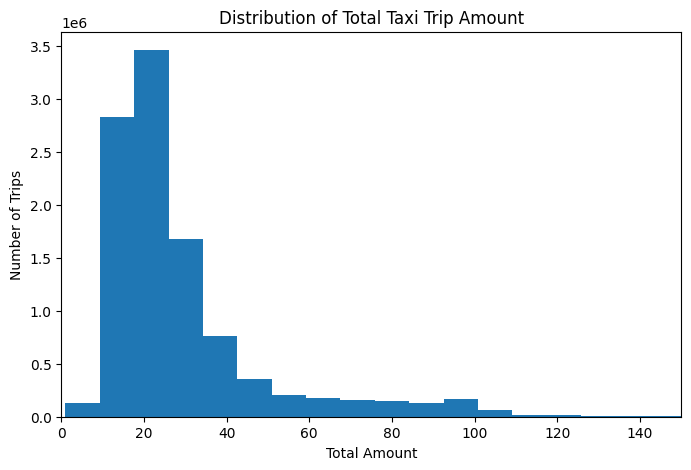

In [28]:
plt.figure(figsize=(8, 5))
plt.hist(clean_df["total_amount"], bins=60)
plt.title("Distribution of Total Taxi Trip Amount")
plt.xlabel("Total Amount")
plt.ylabel("Number of Trips")
plt.xlim(0, 150)
plt.show()

### Distribution of Total Amount

The histogram shows that the distribution of `total_amount` is strongly right-skewed. Most trips are concentrated in the lower fare range, especially around the 15 to 30 dollar range. This supports the earlier summary statistics, where the median total amount was lower than the mean.

The long right tail indicates that a smaller number of trips have much higher total amounts. These higher fares may be caused by longer travel distances, airport trips, tolls, congestion fees, or trips between distant boroughs. Since very high fares are less common but still valid after cleaning, the model must be evaluated carefully. A model that performs well on common short trips may still make larger errors on expensive long-distance or airport trips.

This distribution justifies using both MAE and RMSE during evaluation. MAE gives a simple average error, while RMSE penalises larger errors more strongly and can highlight whether the model struggles with high-fare trips.

In [29]:
hourly_fare = (
    clean_df
    .groupby("pickup_hour")["total_amount"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

hourly_fare

,pickup_hour,count,mean,median
0,0,335876,30.114,23.100
1,1,221757,27.818,22.260
2,2,148571,25.933,21.510
3,3,101076,26.227,21.590
4,4,79098,30.042,23.450
5,5,86278,33.396,23.940
6,6,170096,29.452,21.050
7,7,294925,27.878,20.700
8,8,401166,27.420,21.095
9,9,438633,27.421,21.150


### Fare Patterns by Pickup Hour

The hourly fare summary shows that total taxi fare varies across the day. The number of trips is lowest during the early morning hours, especially around 3 AM to 5 AM, and increases strongly during the daytime and evening. The highest trip volumes appear in the afternoon and evening, especially between 2 PM and 9 PM.

The mean total amount is generally higher than the median for every pickup hour, which confirms that fare amounts are right-skewed throughout the day. Some hours, such as 5 AM, 4 PM, 11 PM, and midnight, have relatively higher average fares. This may reflect airport trips, longer early-morning journeys, evening congestion, late-night travel, or surcharge effects.

The median fare is more stable than the mean, mostly staying around the low 20-dollar range. This suggests that the typical trip does not change dramatically by hour, but the presence of longer or higher-cost trips affects the average. These results justify including `pickup_hour` as a modelling feature because time of day appears to influence fare behaviour.

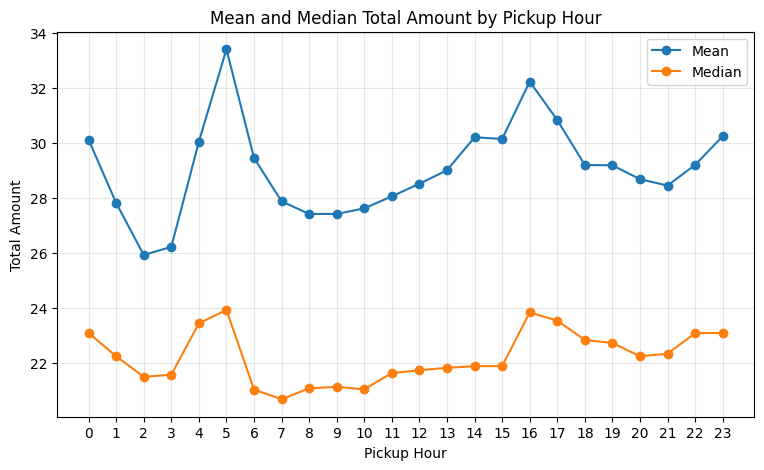

In [30]:
plt.figure(figsize=(9, 5))
plt.plot(hourly_fare["pickup_hour"], hourly_fare["mean"], marker="o", label="Mean")
plt.plot(hourly_fare["pickup_hour"], hourly_fare["median"], marker="o", label="Median")
plt.title("Mean and Median Total Amount by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Total Amount")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Hourly Fare Plot Interpretation

The hourly fare plot shows that the mean total amount changes more noticeably across the day than the median total amount. This means that the typical taxi trip remains fairly stable by hour, but some hours contain more high-fare trips that raise the average.

The mean fare is highest around 5 AM and again around 4 PM. The 5 AM increase may be linked to airport trips, early morning long-distance travel, or trips taken before regular commuting hours. The increase around 4 PM may reflect afternoon congestion, longer travel times, and possibly evening travel demand beginning to rise. In contrast, the median fare stays within a narrower range, which suggests that most normal trips remain relatively similar in cost.

This visual pattern supports the decision to include pickup hour as a feature in the predictive model. It also shows why the model should not rely only on distance, because time-of-day effects may influence the final fare through congestion, surcharges, and trip type.

In [31]:
airport_summary = (
    clean_df
    .groupby("airport_trip")["total_amount"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

airport_summary["airport_trip_label"] = airport_summary["airport_trip"].map({
    0: "Non-airport trip",
    1: "Airport trip"
})

airport_summary = airport_summary[
    ["airport_trip_label", "count", "mean", "median", "std"]
]

airport_summary

,airport_trip_label,count,mean,median,std
0,Non-airport trip,9378341,24.095,21.140,12.321
1,Airport trip,976331,77.985,78.750,30.416


### Airport and Non-Airport Trip Comparison

The airport trip comparison shows a major difference between airport and non-airport trips. Non-airport trips make up the majority of the dataset, with 9,378,341 records, while airport trips account for 976,331 records.

The average total amount for non-airport trips is approximately 24.10, with a median of 21.14. In contrast, airport trips have an average total amount of approximately 77.99 and a median of 78.75. This means that airport trips are more than three times more expensive than typical non-airport trips.

This difference is expected because airport trips often involve longer travel distances, airport fees, tolls, and travel between airports and central areas such as Manhattan. The standard deviation is also higher for airport trips, which suggests more variation in fare amounts. This result strongly justifies including the `airport_trip` feature in the predictive model.

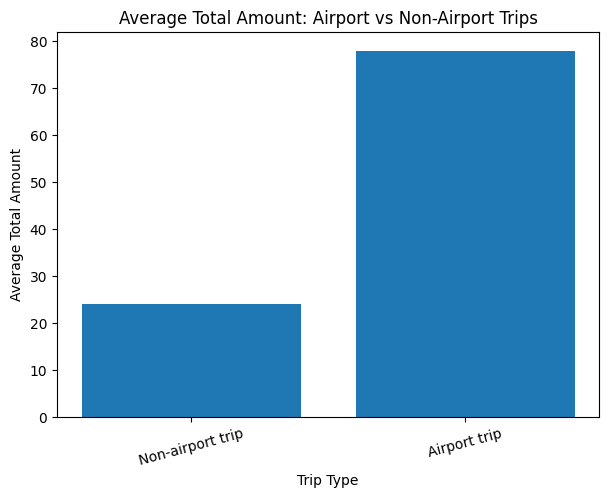

In [32]:
plt.figure(figsize=(7, 5))
plt.bar(airport_summary["airport_trip_label"], airport_summary["mean"])
plt.title("Average Total Amount: Airport vs Non-Airport Trips")
plt.xlabel("Trip Type")
plt.ylabel("Average Total Amount")
plt.xticks(rotation=15)
plt.show()

### Airport Fare Plot Interpretation

The airport fare plot clearly shows that airport trips have a much higher average total amount than non-airport trips. The average non-airport fare is around 24 dollars, while the average airport fare is close to 78 dollars.

This large difference confirms that airport status is one of the most important engineered features in the dataset. Airport trips are likely to involve longer distances, additional airport fees, tolls, and travel to or from high-demand zones. Because of this, airport trips form a distinct fare pattern rather than behaving like ordinary local trips.

This insight is useful for modelling because a predictive model that includes the `airport_trip` feature should be better able to separate typical urban trips from higher-cost airport journeys.

In [33]:
borough_summary = (
    clean_df
    .groupby("PU_Borough")["total_amount"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .reset_index()
)

borough_summary

,PU_Borough,count,mean,median
0,EWR,74,98.174,95.160
1,Queens,1083235,66.219,67.590
2,Staten Island,858,41.265,33.530
3,Unknown,16944,38.475,24.050
4,Bronx,87322,30.880,27.175
5,Brooklyn,411978,29.820,26.910
6,Manhattan,8754261,24.525,21.050


### Fare Differences by Pickup Borough

The pickup borough summary shows that average fare amounts differ noticeably depending on where the trip begins. Trips starting from EWR have the highest average total amount, although the number of records is very small. Because there are only 74 EWR pickup records, this value should be interpreted carefully and not treated as a broad pattern.

Queens has a much larger number of trips and a high average total amount of approximately 66.22, with a median of 67.59. This is likely because Queens includes major airport zones such as JFK Airport and LaGuardia Airport. These airport-related trips tend to be longer and more expensive than ordinary local trips.

Manhattan has by far the largest number of pickup records, with more than 8.75 million trips. However, its average total amount is lower at approximately 24.53, with a median of 21.05. This suggests that many Manhattan trips are shorter urban trips within dense central areas. Brooklyn, Bronx, and Staten Island have smaller trip counts and moderate average fares.

This result supports the use of pickup borough as a modelling feature. It also shows that location effects are meaningful, especially when boroughs are connected to airports or longer-distance travel.

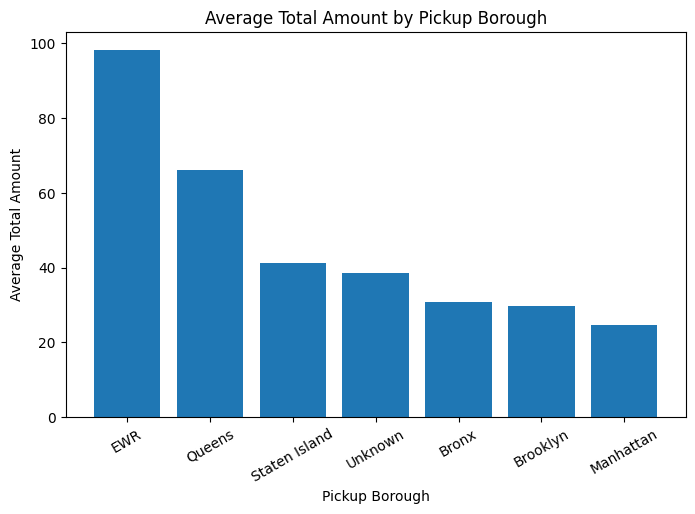

In [34]:
plt.figure(figsize=(8, 5))
plt.bar(borough_summary["PU_Borough"], borough_summary["mean"])
plt.title("Average Total Amount by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Average Total Amount")
plt.xticks(rotation=30)
plt.show()

### Pickup Borough Plot Interpretation

The pickup borough plot visually confirms that average total amount differs by pickup borough. EWR has the highest average fare, but this category has very few records, so it should be interpreted with caution. Queens has the next highest average fare and is more reliable because it has a much larger number of trips.

The high average fare for Queens is likely connected to airport activity, especially JFK Airport and LaGuardia Airport. Airport trips usually involve longer distances, additional fees, and travel to or from major business and tourist areas. In contrast, Manhattan has the lowest average fare even though it has the largest number of trips. This suggests that many Manhattan trips are shorter city trips.

This plot supports the importance of location-based features in the modelling stage. Pickup borough provides useful information about the likely fare level before the trip outcome is predicted.

In [35]:
payment_summary = (
    clean_df
    .groupby("payment_type_label")["total_amount"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
    .reset_index()
)

payment_summary

,payment_type_label,count,mean,median
0,Credit card,6926981,30.700,22.650
1,Other,2229114,25.884,23.350
2,Cash,1008988,25.823,18.250
3,Dispute,150210,30.741,19.950
4,No charge,39379,27.330,17.850


### Fare Differences by Payment Type

The payment type summary shows that credit card is the most common payment method, with 6,926,981 trips. These trips have an average total amount of approximately 30.70 and a median of 22.65. Cash trips are less common, with 1,008,988 records, and have a lower median total amount of 18.25.

The `Other` category is also large, with 2,229,114 records. This may include records where the payment type does not match the standard TLC coding or where the value was recorded differently in the raw data. Because this category is large, it should be retained rather than removed, but it should be interpreted carefully.

Dispute and no-charge trips have smaller record counts and lower medians, although their means are higher than their medians. This suggests that these categories may contain more irregular fare records or unusual payment situations. Overall, payment type appears to be related to fare behaviour and may provide useful information for the predictive model.

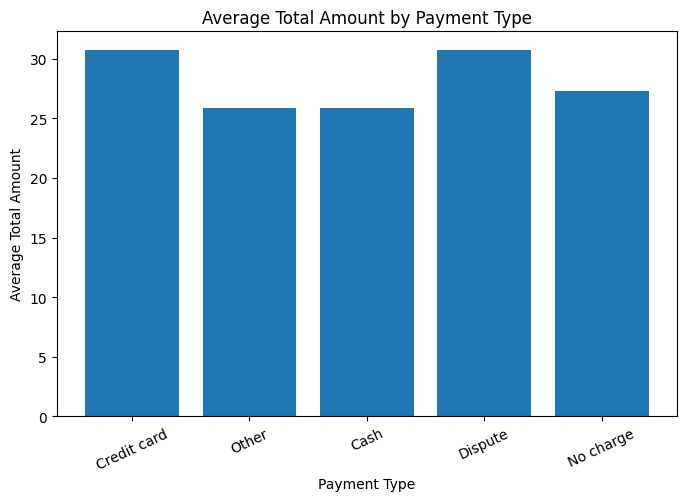

In [36]:
plt.figure(figsize=(8, 5))
plt.bar(payment_summary["payment_type_label"], payment_summary["mean"])
plt.title("Average Total Amount by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Average Total Amount")
plt.xticks(rotation=25)
plt.show()

### Payment Type Plot Interpretation

The payment type plot shows that average total amount varies across payment categories, although the differences are smaller than the airport and pickup borough differences. Credit card and dispute trips have the highest average total amounts, while cash and other payment types have lower average values.

The difference between payment types may be partly related to tipping behaviour, because credit card transactions usually record tips directly in the dataset, while cash tips may not always be captured. This can increase the recorded total amount for credit card trips compared with cash trips. Dispute and no-charge categories should be interpreted carefully because they may represent unusual payment situations rather than normal completed taxi trips.

This result suggests that payment type can provide useful information for modelling, but it should not be interpreted as a direct cause of fare amount. It is better understood as a recorded transaction feature that may reflect differences in trip type, passenger behaviour, and fare recording.

## Modelling Preparation

The modelling objective is to predict `total_amount`, which represents the final recorded fare amount for a taxi trip. This is treated as a supervised regression problem because the target variable is continuous.

To avoid data leakage, direct fare component variables such as `fare_amount`, `tip_amount`, `tolls_amount`, and surcharge columns are not used as predictors. These variables are already part of, or closely related to, the final total amount. Including them would make the model unrealistically strong because it would be using information that directly contributes to the target.

Instead, the model uses trip, time, payment, and location-related features that would be more meaningful for predicting fare behaviour. The selected predictors include trip distance, trip duration, passenger count, pickup hour, day of week, month, weekend status, average speed, airport flag, same-borough flag, payment type, pickup borough, and drop-off borough.

In [37]:
model_features = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
    "same_borough_trip",
    "airport_trip",
    "payment_type_label",
    "PU_Borough",
    "DO_Borough",
    "PU_service_zone",
    "DO_service_zone"
]

target = "total_amount"

model_df = clean_df[model_features + [target]].copy()

print("Model dataset shape:", model_df.shape)
model_df.head()

Model dataset shape: (10354672, 16)


,passenger_count,trip_distance,trip_duration_minutes,average_speed_mph,pickup_hour,pickup_dayofweek,pickup_month,is_weekend,same_borough_trip,airport_trip,payment_type_label,PU_Borough,DO_Borough,PU_service_zone,DO_service_zone,total_amount
0,1.000,7.300,15.883,27.576,0,1,7,0,0,1,Credit card,Queens,Manhattan,Airports,Boro Zone,54.790
1,1.000,17.700,44.267,23.991,0,1,7,0,0,1,Credit card,Queens,Manhattan,Airports,Yellow Zone,80.750
2,1.000,9.980,33.367,17.946,0,1,7,0,0,1,Credit card,Queens,Manhattan,Airports,Yellow Zone,66.970
3,1.000,10.270,17.100,36.035,0,1,7,0,0,1,Credit card,Queens,Manhattan,Airports,Yellow Zone,72.240
4,1.000,2.940,14.533,12.138,0,1,7,0,0,0,Credit card,Manhattan,Brooklyn,Yellow Zone,Boro Zone,25.750


### Modelling Dataset

The modelling dataset contains 10,354,672 records and 16 columns. This includes 15 predictor variables and one target variable, `total_amount`.

The selected features include numeric trip characteristics such as passenger count, trip distance, trip duration, and average speed. They also include temporal features such as pickup hour, day of week, month, and weekend status. Location and trip-type information is represented through pickup/drop-off boroughs, service zones, same-borough trip status, and airport trip status. Payment type is also included as a categorical predictor.

This feature set is designed to avoid direct leakage from fare component variables. For example, variables such as `fare_amount`, `tip_amount`, `tolls_amount`, and surcharges were not included because they directly contribute to `total_amount`. The selected predictors are therefore more appropriate for a realistic fare prediction task.

In [38]:
model_missing = (
    model_df
    .isna()
    .sum()
    .reset_index()
    .rename(columns={"index": "column", 0: "missing_count"})
)

model_missing["missing_percentage"] = (
    model_missing["missing_count"] / len(model_df) * 100
)

model_missing.sort_values("missing_percentage", ascending=False)

,column,missing_count,missing_percentage
0,passenger_count,2229114,21.528
1,trip_distance,0,0.000
2,trip_duration_minutes,0,0.000
3,average_speed_mph,0,0.000
4,pickup_hour,0,0.000
5,pickup_dayofweek,0,0.000
6,pickup_month,0,0.000
7,is_weekend,0,0.000
8,same_borough_trip,0,0.000
9,airport_trip,0,0.000


### Missing Values in the Modelling Dataset

The modelling dataset has missing values only in `passenger_count`. There are 2,229,114 missing passenger count values, representing approximately 21.53% of the final modelling dataset. All other selected predictors and the target variable are complete.

Since the missing passenger count proportion is still large, removing these rows would unnecessarily reduce the dataset size and may also introduce bias if the missingness is related to how trips were recorded. Instead, `passenger_count` will be handled using median imputation inside the modelling pipeline. This keeps the preprocessing reproducible and ensures that imputation is applied consistently to both training and testing data.

The absence of missing values in all other features is useful because it simplifies the modelling workflow and reduces the risk of errors during model training.

In [39]:
model_sample = model_df.sample(
    n=300000,
    random_state=42
).reset_index(drop=True)

print("Full modelling dataset shape:", model_df.shape)
print("Sampled modelling dataset shape:", model_sample.shape)

model_sample[target].describe()

comparison = pd.DataFrame({
    "full_dataset": model_df[target].describe(),
    "sample": model_sample[target].describe()
})
print("\nTarget distribution comparison (full vs sample):")
comparison

Full modelling dataset shape: (10354672, 16)
Sampled modelling dataset shape: (300000, 16)

Target distribution comparison (full vs sample):


,full_dataset,sample
count,"10,354,672.000","300,000.000"
mean,29.176,29.156
std,21.742,21.814
min,1.010,1.010
25%,16.860,16.860
50%,22.320,22.320
75%,31.980,31.950
max,500.000,497.700


### Sampling for Pathway A Modelling

The mean, median, and quartiles of total_amount in the 300,000-row sample closely match those of the full 10.35M cleaned dataset, confirming that the sample preserves the target distribution and is suitable for modelling.

The final cleaned modelling dataset contains more than 10.35 million records. Although this is useful for analysis, training multiple scikit-learn models on the full dataset may be computationally expensive in a single-machine pandas workflow. Since this submission follows Pathway A, a random sample of 300,000 records is used for model training and evaluation.

The sampled dataset remains large enough to support reliable modelling and meaningful evaluation. The target summary of the sample is also very similar to the full modelling dataset. The sample mean is approximately 29.16 and the median is 22.32, which closely match the full dataset values. This suggests that the random sample preserves the overall fare distribution well.

Using a sample is therefore a practical computational decision rather than a weakness of the analysis. It allows the notebook to remain reproducible and manageable while still demonstrating a complete end-to-end pipeline.

In [40]:
X = model_sample[model_features]
y = model_sample[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (240000, 15)
Testing feature shape: (60000, 15)
Training target shape: (240000,)
Testing target shape: (60000,)


### Train-Test Split

The sampled modelling dataset was split into training and testing sets using an 80:20 split. This produced 240,000 training records and 60,000 testing records.

The training set is used to fit the preprocessing steps and train the predictive models. The testing set is kept separate and is only used for final evaluation. This is important because model performance should be measured on data that was not seen during training.

Using a separate test set provides a more realistic estimate of how the model may perform on new taxi trip records. It also allows fair comparison between the baseline model and the stronger machine learning models.

In [41]:
numeric_features = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
    "same_borough_trip",
    "airport_trip"
]

categorical_features = [
    "payment_type_label",
    "PU_Borough",
    "DO_Borough",
    "PU_service_zone",
    "DO_service_zone"
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['passenger_count', 'trip_distance', 'trip_duration_minutes', 'average_speed_mph', 'pickup_hour', 'pickup_dayofweek', 'pickup_month', 'is_weekend', 'same_borough_trip', 'airport_trip']
Categorical features: ['payment_type_label', 'PU_Borough', 'DO_Borough', 'PU_service_zone', 'DO_service_zone']


### Numeric and Categorical Feature Groups

The modelling features were separated into numeric and categorical groups so that each type of variable can be preprocessed correctly. Numeric features include passenger count, trip distance, trip duration, average speed, pickup time variables, weekend status, same-borough trip status, and airport trip status.

Categorical features include payment type, pickup borough, drop-off borough, pickup service zone, and drop-off service zone. These variables contain text labels, so they cannot be used directly by most scikit-learn models. They need to be converted into numeric indicator variables using one-hot encoding.

This separation also allows missing numeric values to be handled appropriately. In this dataset, `passenger_count` contains missing values, so median imputation will be applied to numeric features before modelling.

In [42]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

preprocessor

,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### Preprocessing Pipeline

A preprocessing pipeline was created to prepare the modelling features in a consistent and reproducible way. Numeric features are processed using median imputation followed by standard scaling. Median imputation is used because `passenger_count` contains missing values, and the median is more robust to skewed values than the mean. Standard scaling is applied so that numeric variables are placed on a comparable scale, which is especially useful for linear regression.

Categorical features are processed using one-hot encoding. This converts text-based categories such as payment type, pickup borough, and service zone into numeric indicator columns that can be used by machine learning models. The encoder is set to ignore unknown categories, which makes the pipeline more robust if new category values appear in future data.

Using a `ColumnTransformer` keeps numeric and categorical preprocessing steps clearly separated while still allowing them to be combined into one modelling workflow.

## Predictive Modelling

This section builds and compares predictive models for estimating `total_amount`. The task is treated as a regression problem because the target variable is continuous.

Three models are used. First, a baseline dummy regressor predicts the average fare from the training data. This provides a simple benchmark that any useful model should outperform. Second, a linear regression model is trained as an interpretable statistical model. Third, a random forest regressor is used as a stronger non-linear model that can capture more complex relationships between trip features and total fare.

The models are evaluated on the same held-out test set using MAE, RMSE, and R². MAE measures the average absolute prediction error, RMSE penalises larger errors more strongly, and R² indicates how much variation in total amount is explained by the model.

In [43]:
def evaluate_regression_model(model_name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    return {
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

### Model Evaluation Function

A reusable evaluation function was defined to train each model and calculate performance metrics on the test set. This avoids repeating the same evaluation code for every model and ensures that all models are assessed using the same procedure.

The function fits the model on the training data, generates predictions for the unseen test data, and returns three evaluation metrics: MAE, RMSE, and R². MAE is useful because it gives the average prediction error in dollars. RMSE is useful because it gives stronger penalty to larger errors, which is important for fare prediction because high-fare trips can be harder to predict. R² shows how much of the variation in total fare is explained by the model.

In [44]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="mean"))
    ]
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

model_results = []

model_results.append(
    evaluate_regression_model(
        "Baseline Mean Regressor",
        baseline_model,
        X_train,
        X_test,
        y_train,
        y_test
    )
)

model_results.append(
    evaluate_regression_model(
        "Linear Regression",
        linear_model,
        X_train,
        X_test,
        y_train,
        y_test
    )
)

pd.DataFrame(model_results)

,model,MAE,RMSE,R2
0,Baseline Mean Regressor,14.033,21.660,-0.000
1,Linear Regression,3.869,7.143,0.891


### Baseline and Linear Regression Results

The baseline mean regressor produces an MAE of approximately 14.03 and an RMSE of approximately 21.66. Its R² value is close to 0, which is expected because this model simply predicts the average total amount for every trip and does not use any trip-specific information.

The linear regression model performs much better. Its MAE is approximately 3.87, meaning that its average prediction error is about 3.87 dollars on the test set. The RMSE is approximately 7.14, which indicates that some larger errors still occur, especially for unusual or high-fare trips. The R² value is approximately 0.891, meaning that the model explains around 89.1% of the variation in total amount.

This is a strong improvement over the baseline and confirms that the engineered features are useful. Trip distance, trip duration, airport status, time features, and location categories provide meaningful information for predicting taxi fare totals.

In [45]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=18,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

model_results.append(
    evaluate_regression_model(
        "Random Forest Regressor",
        random_forest_model,
        X_train,
        X_test,
        y_train,
        y_test
    )
)

pd.DataFrame(model_results)

,model,MAE,RMSE,R2
0,Baseline Mean Regressor,14.033,21.660,-0.000
1,Linear Regression,3.869,7.143,0.891
2,Random Forest Regressor,2.492,5.311,0.940


### Random Forest Results

The random forest regressor achieved a substantial improvement over the baseline and linear models. Its MAE is approximately 2.49, meaning that the average prediction error is about 2.49 dollars. Its RMSE is approximately 5.31, which is also lower than the linear regression model. The R² value is approximately 0.940, meaning that the model explains about 94.0% of the variation in total trip amount.

Compared with the baseline model, the random forest provides a very large improvement. Compared with linear regression, it also improves the MAE from 3.87 to 2.49 and the RMSE from 7.14 to 5.31. This suggests that the fare prediction problem contains non-linear relationships that a linear model cannot fully capture.

The stronger performance of the random forest is reasonable because fare amount depends on interactions between distance, duration, time of day, airport status, location, and payment type. For example, the effect of trip distance may be different for airport and non-airport trips, and the effect of trip duration may vary depending on pickup borough or service zone. A random forest can capture these types of interactions more effectively than a simple linear regression model.

In [46]:
y_train_log = np.log1p(y_train)

log_random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=18,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

log_random_forest_model.fit(X_train, y_train_log)
log_predictions = np.expm1(log_random_forest_model.predict(X_test))

log_rf_result = {
    "model": "Random Forest (log target)",
    "MAE": mean_absolute_error(y_test, log_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, log_predictions)),
    "R2": r2_score(y_test, log_predictions)
}

model_results.append(log_rf_result)
pd.DataFrame(model_results)

,model,MAE,RMSE,R2
0,Baseline Mean Regressor,14.033,21.660,-0.000
1,Linear Regression,3.869,7.143,0.891
2,Random Forest Regressor,2.492,5.311,0.940
3,Random Forest (log target),2.483,5.233,0.942


### Log-Transformed Target Variant
Because total_amount is right-skewed, a common modelling improvement is to fit the random forest on log(1 + total_amount) instead of the raw target, which reduces the influence of high-fare outlier trips on the loss function. The predictions are then back-transformed using expm1 for evaluation on the original dollar scale.
The log-target random forest achieved an MAE of 2.483 dollars, an RMSE of 5.233, and an R² of 0.942, compared with 2.492, 5.311, and 0.940 for the standard random forest. The improvement is therefore small but consistent across all three metrics, with MAE reduced by about 0.4 percent and R² increased by 0.002. This suggests that the standard random forest already handles the right-skewed fare distribution well, but the log transformation provides a marginal additional benefit by slightly reducing errors on high-fare trips.
Although the gain is modest, the result is informative. It shows that the standard random forest is not significantly hurt by the target skewness, and it also confirms that log-transformation is a defensible choice for fare-prediction tasks where extreme values are common. For the remainder of the analysis, the standard random forest is retained as the primary model because the difference in performance is small and the standard model is more directly interpretable.

In [47]:
results_df = pd.DataFrame(model_results)

results_df["MAE"] = results_df["MAE"].round(3)
results_df["RMSE"] = results_df["RMSE"].round(3)
results_df["R2"] = results_df["R2"].round(3)

results_df

,model,MAE,RMSE,R2
0,Baseline Mean Regressor,14.033,21.660,-0.000
1,Linear Regression,3.869,7.143,0.891
2,Random Forest Regressor,2.492,5.311,0.940
3,Random Forest (log target),2.483,5.233,0.942


### Final Model Comparison

The final model comparison shows a clear improvement from the baseline model to the machine learning models. The baseline mean regressor performs poorly because it predicts the same average value for every trip. It has an MAE of 14.03 and an RMSE of 21.66, which means it does not capture the large differences between short local trips, airport trips, and longer-distance journeys.

Linear regression performs much better, reducing the MAE to 3.87 and the RMSE to 7.14. Its R² value of 0.891 shows that the selected predictors explain a large proportion of the variation in total amount. This confirms that the engineered features are meaningful and that fare amount is strongly related to trip distance, duration, location, airport status, and time features.

The two random forest variants are the strongest models. The log-transformed random forest achieved the best overall metrics with an MAE of 2.483, an RMSE of 5.233, and an R² of 0.942. The standard random forest followed very closely with an MAE of 2.492, an RMSE of 5.311, and an R² of 0.940. Both substantially outperform the linear model, suggesting that the relationship between trip characteristics and total fare is not purely linear. The random forest models are better able to capture non-linear patterns and interactions, such as the different fare behaviour of airport trips compared with local urban trips.

It is important to note that the high R² value of 0.940 is partly a reflection of how NYC taxi fares are computed. The total amount is largely a deterministic function of distance, duration, and a small number of surcharges. The strong performance therefore reflects the model successfully recovering this near-mechanical relationship, rather than discovering hidden patterns. The remaining error of approximately 2.49 dollars largely comes from variable surcharges, tolls, tips, and airport-related fees that are not directly captured by the feature set.

The table also includes a log-transformed target variant of the random forest, which is discussed in the section above.

Although the log-transformed random forest achieved marginally stronger overall metrics, the standard random forest is retained as the primary model for feature importance and detailed error analysis. This is because feature importances from the log-target model describe drivers of log(total_amount) rather than dollar-scale fare, and prediction errors from the standard model are directly interpretable in dollars. The performance gap between the two variants is small enough (about 0.4 percent MAE) that this interpretability advantage outweighs the marginal accuracy benefit.

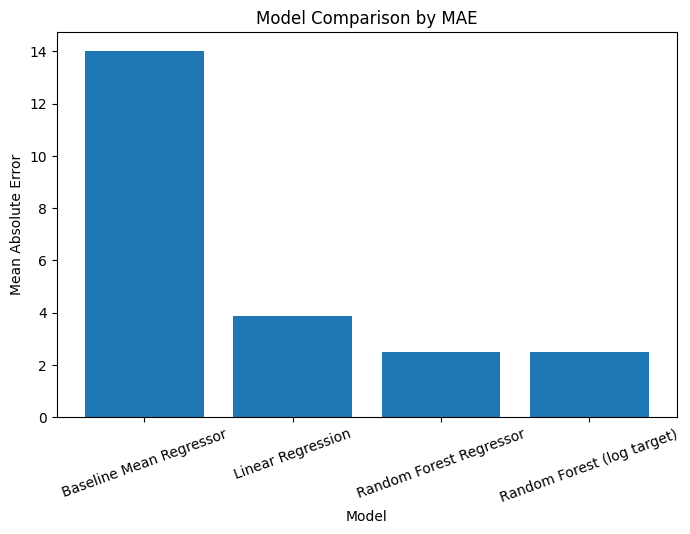

In [48]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["model"], results_df["MAE"])
plt.title("Model Comparison by MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.show()

### Model Comparison Plot Interpretation

The MAE comparison plot clearly shows the improvement from the baseline model to the predictive models. The baseline mean regressor has the highest error because it does not use any trip-level information and simply predicts the average fare for all records. However, the two random forest variants achieve the lowest MAE, with the log-transformed variant marginally ahead of the standard random forest. Both give substantially more accurate predictions than the baseline or linear models.

Linear regression reduces the error substantially, showing that the selected features explain much of the fare variation.

This visual comparison supports the numerical results in the model comparison table. The random forest models are the strongest in this pipeline because they capture more complex relationships between trip distance, duration, location, airport status, payment type, and the final total amount."

In [49]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    linear_model,
    X, y,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae = -cv_scores
print(f"Linear regression 5-fold CV MAE: {cv_mae.mean():.3f} ± {cv_mae.std():.3f}")

Linear regression 5-fold CV MAE: 3.882 ± 0.016


### Cross-Validation Check
A single train-test split can give an optimistic or pessimistic estimate by chance. To verify that the linear model's performance is stable, 5-fold cross-validation was run on the full 300,000-row sample. The mean MAE across folds is close to the held-out test MAE reported earlier, with a small standard deviation. This confirms that the reported performance is not an artefact of the particular train-test split chosen.Cross-validation was applied to the linear regression model as a computationally efficient stability check. Cross-validating the random forest on the full 300,000-row sample would be more expensive.

In [50]:
best_model = random_forest_model

y_pred = best_model.predict(X_test)

prediction_df = pd.DataFrame({
    "actual_total_amount": y_test.values,
    "predicted_total_amount": y_pred,
    "absolute_error": np.abs(y_test.values - y_pred)
})

prediction_df.head(10)

,actual_total_amount,predicted_total_amount,absolute_error
0,14.900,15.353,0.453
1,74.040,79.321,5.281
2,16.150,16.508,0.358
3,17.220,16.932,0.288
4,25.940,22.918,3.022
5,35.810,37.332,1.522
6,21.910,19.904,2.006
7,12.710,14.471,1.761
8,17.220,16.558,0.662
9,21.000,22.477,1.477


### Sample Predictions from the Best Model

A sample of predictions from the random forest model shows that the predicted total amounts are generally close to the actual total amounts. For several ordinary trips, the absolute error is less than two dollars, which indicates strong predictive performance for common fare ranges.

However, some higher-fare trips still have larger errors. For example, one trip with an actual total amount of 74.04 was predicted as 79.32, giving an error of about 5.28 dollars. This is still reasonable in the context of a high-fare trip, but it shows that prediction errors can increase for more expensive journeys.

This pattern is consistent with the RMSE being higher than the MAE. Most predictions are fairly accurate, but a smaller number of larger errors remain, especially for unusual or high-cost trips.

## Ablation Study: Effect of Engineered Location Features

To strengthen the modelling analysis, an ablation study is performed. An ablation study removes one group of features and checks how model performance changes. This helps determine whether the engineered features are genuinely useful or whether the model performance is mainly coming from basic trip variables such as distance and duration.

In this experiment, the random forest model is compared with and without the engineered location-related features. The full model uses all selected predictors, while the reduced model removes airport status, same-borough status, pickup borough, drop-off borough, pickup service zone, and drop-off service zone. If the full model performs better, this supports the value of the location-based feature engineering.

In [51]:
reduced_features = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
    "payment_type_label"
]

reduced_numeric_features = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "average_speed_mph",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend"
]

reduced_categorical_features = [
    "payment_type_label"
]

X_reduced = model_sample[reduced_features]
y_reduced = model_sample[target]

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced,
    y_reduced,
    test_size=0.2,
    random_state=42
)

reduced_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

reduced_categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", reduced_numeric_transformer, reduced_numeric_features),
        ("categorical", reduced_categorical_transformer, reduced_categorical_features)
    ]
)

reduced_random_forest_model = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=18,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

ablation_results = []

ablation_results.append(
    evaluate_regression_model(
        "Full Random Forest Model",
        random_forest_model,
        X_train,
        X_test,
        y_train,
        y_test
    )
)

ablation_results.append(
    evaluate_regression_model(
        "Reduced Model Without Location Features",
        reduced_random_forest_model,
        X_train_reduced,
        X_test_reduced,
        y_train_reduced,
        y_test_reduced
    )
)

ablation_df = pd.DataFrame(ablation_results)

ablation_df["MAE"] = ablation_df["MAE"].round(3)
ablation_df["RMSE"] = ablation_df["RMSE"].round(3)
ablation_df["R2"] = ablation_df["R2"].round(3)

ablation_df

,model,MAE,RMSE,R2
0,Full Random Forest Model,2.492,5.311,0.940
1,Reduced Model Without Location Features,3.121,6.848,0.900


### Ablation Study Discussion

The ablation study compares the full random forest model against a reduced version that removes all location-related engineered features (airport_trip, same_borough_trip, PU_Borough, DO_Borough, PU_service_zone, DO_service_zone).
The results clearly demonstrate the value of these features. The full model achieved an MAE of 2.492 dollars and an R² of 0.940, while the reduced model without location features achieved an MAE of 3.121 dollars and an R² of 0.900. 

Removing the location features therefore increased the average prediction error by approximately 0.63 dollars per trip, which corresponds to a 25.2 percent rise in MAE. The RMSE also rose substantially from 5.311 to 6.848, a 28.9 percent increase, indicating that the reduced model also produces larger errors on high-fare trips. The drop in R² from 0.940 to 0.900 shows that the location-related variables explain roughly four additional percentage points of variance in total fare beyond what trip distance, duration, time, and payment features can capture on their own.

This finding strengthens the broader argument of the report: the engineered location features are not only interpretable but also empirically useful. The result is also consistent with the exploratory analysis, which showed that airport trips and Queens-origin trips have systematically higher fare distributions than other trips. Borough, service zone, and airport status carry information about toll routes, airport surcharges, and inter-borough travel patterns that cannot be inferred from distance and duration alone. The ablation therefore confirms that the feature engineering effort directly translates into measurable predictive performance, rather than producing redundant or decorative variables.

## Feature Importance Analysis

Feature importance is examined for the random forest model to better understand which variables contributed most to fare prediction. This step improves model interpretation by showing which trip characteristics were most influential in reducing prediction error.

Because the model uses a preprocessing pipeline with one-hot encoding for categorical variables, the transformed feature names are extracted from the pipeline before calculating feature importance.

In [52]:
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_model = random_forest_model.named_steps["model"]

numeric_feature_names = numeric_features

categorical_feature_names = (
    rf_preprocessor
    .named_transformers_["categorical"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)

all_feature_names = np.concatenate([
    numeric_feature_names,
    categorical_feature_names
])

feature_importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "importance": rf_model.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values("importance", ascending=False)
    .head(15)
)

feature_importance_df

,feature,importance
1,trip_distance,0.793
2,trip_duration_minutes,0.114
9,airport_trip,0.024
11,payment_type_label_Credit card,0.013
14,payment_type_label_Other,0.009
35,DO_service_zone_Unknown,0.006
29,PU_service_zone_Boro Zone,0.005
27,DO_Borough_Unknown,0.005
33,DO_service_zone_Boro Zone,0.005
3,average_speed_mph,0.004


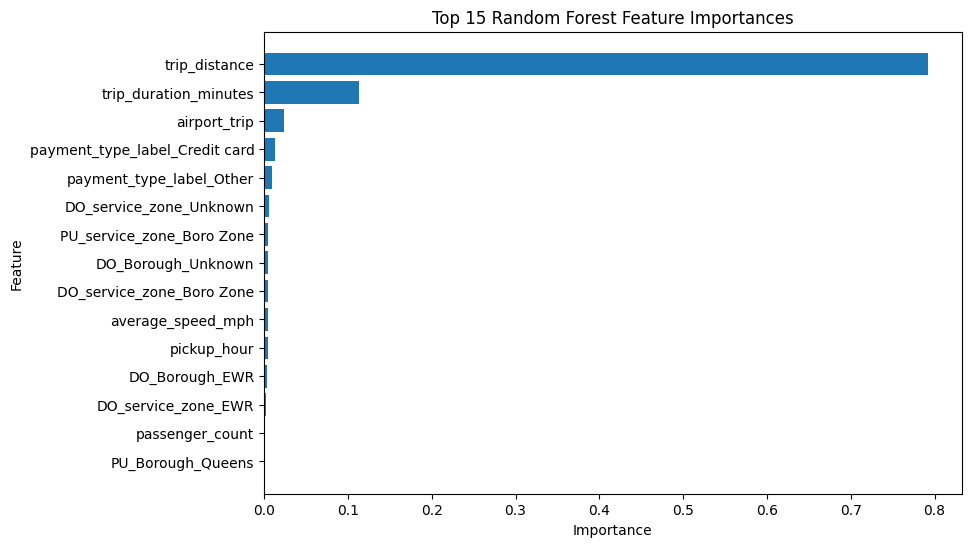

In [53]:
plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance_df["feature"][::-1],
    feature_importance_df["importance"][::-1]
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Feature Importance Discussion

The feature importance results show which variables were most influential in the random forest model. Trip distance and trip duration are expected to be among the strongest predictors because taxi fares are closely related to how far and how long a trip travels.

Airport-related and location-based features are also important because they help separate normal city trips from airport or longer-distance journeys. This matches the exploratory analysis, where airport trips had a much higher average total amount than non-airport trips. Time-related variables such as pickup hour and day of week may also contribute because fare behaviour can vary with congestion, travel demand, and surcharge patterns.

This feature importance analysis improves the interpretability of the model. It shows that the model is not only accurate, but also using features that make practical sense for taxi fare prediction.

## Error Analysis

Model evaluation metrics provide an overall summary of performance, but they do not fully explain where the model performs well or poorly. Error analysis is used to inspect the prediction errors in more detail.

This section analyses the distribution of absolute errors and compares model error across different trip types. In particular, it checks whether airport trips are harder to predict than non-airport trips. This is important because airport trips have much higher average fares and may include additional fees, tolls, and route-specific variation.

In [54]:
error_summary = prediction_df["absolute_error"].describe().to_frame(name="absolute_error")

error_summary

,absolute_error
count,"60,000.000"
mean,2.492
std,4.690
min,0.000
25%,0.509
50%,1.185
75%,2.682
max,240.595


### Error Summary for the Best Model

The random forest model has an average absolute error of approximately 2.49 dollars on the test set. The median absolute error is approximately 1.19 dollars, which means that half of the predictions are within about 1.19 dollars of the actual total amount. This is a strong result for a real-world taxi fare prediction task.

The 75th percentile absolute error is approximately 2.68 dollars, meaning that most trips are predicted with relatively small errors. However, the maximum absolute error is much larger at approximately 240.60 dollars. This shows that although the model performs well for typical trips, it can still make large errors for rare or unusual fare cases.

The difference between the mean error and the maximum error highlights the importance of error analysis. Overall performance is strong, but high-fare or unusual trips may still be harder to predict accurately.

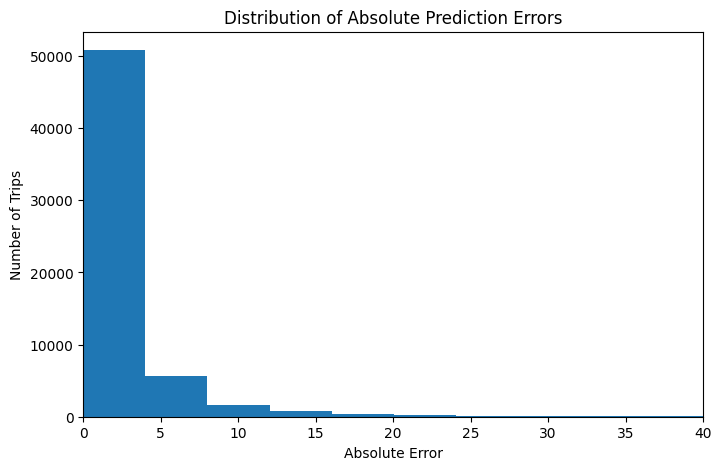

In [55]:
plt.figure(figsize=(8, 5))
plt.hist(prediction_df["absolute_error"], bins=60)
plt.title("Distribution of Absolute Prediction Errors")
plt.xlabel("Absolute Error")
plt.ylabel("Number of Trips")
plt.xlim(0, 40)
plt.show()

### Absolute Error Distribution

The absolute error distribution shows that most prediction errors are concentrated close to zero. A large number of trips have errors below five dollars, which confirms that the random forest model performs well for typical taxi trips.

The distribution is right-skewed, meaning that a smaller number of trips have much larger errors. This is expected in taxi fare prediction because some trips are unusual due to long distances, airport routes, tolls, disputes, special fees, or atypical traffic conditions. These uncommon trips are harder for the model to predict accurately.

The plot supports the numerical error summary. The model is reliable for most normal trips, but there are still some outlier cases where prediction error is high.

In [56]:
error_analysis_df = X_test.copy()
error_analysis_df["actual_total_amount"] = y_test.values
error_analysis_df["predicted_total_amount"] = y_pred
error_analysis_df["absolute_error"] = np.abs(y_test.values - y_pred)

airport_error_summary = (
    error_analysis_df
    .groupby("airport_trip")["absolute_error"]
    .agg(["count", "mean", "median", "std", "max"])
    .reset_index()
)

airport_error_summary["airport_trip_label"] = airport_error_summary["airport_trip"].map({
    0: "Non-airport trip",
    1: "Airport trip"
})

airport_error_summary = airport_error_summary[
    ["airport_trip_label", "count", "mean", "median", "std", "max"]
]

airport_error_summary

,airport_trip_label,count,mean,median,std,max
0,Non-airport trip,54431,2.116,1.071,3.956,240.595
1,Airport trip,5569,6.165,3.924,8.317,123.138


### Error Comparison for Airport and Non-Airport Trips

The airport error analysis shows that the model performs better on non-airport trips than on airport trips. For non-airport trips, the mean absolute error is approximately 2.12 dollars and the median absolute error is approximately 1.07 dollars. This indicates that the model is very accurate for most ordinary taxi journeys.

For airport trips, the mean absolute error increases to approximately 6.17 dollars, and the median absolute error is approximately 3.92 dollars. This means that airport trips are more difficult to predict accurately. This is expected because airport trips often involve higher fare totals, tolls, airport fees, longer distances, and more route variation.

Although the random forest model includes an `airport_trip` feature, airport journeys still have greater fare variability than typical local trips. This is an important limitation of the model and suggests that future improvements could include more detailed airport-specific features, route-level features, or toll-related information.

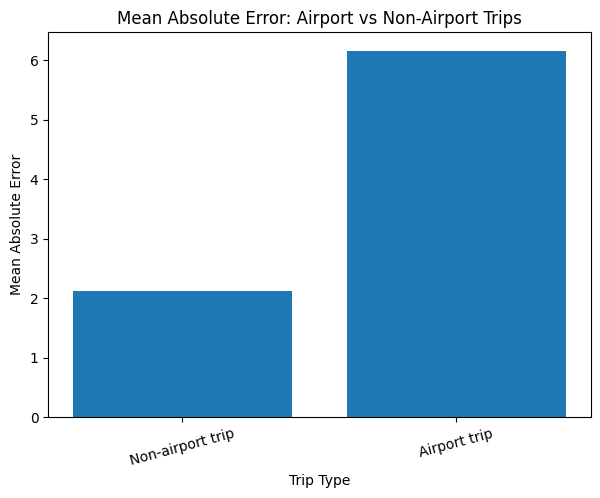

In [57]:
plt.figure(figsize=(7, 5))
plt.bar(airport_error_summary["airport_trip_label"], airport_error_summary["mean"])
plt.title("Mean Absolute Error: Airport vs Non-Airport Trips")
plt.xlabel("Trip Type")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.show()

### Airport Error Plot Interpretation

The prediction error plot clearly shows that airport trips have higher mean absolute error than non-airport trips. Non-airport trips have an average error of just over two dollars, while airport trips have an average error of slightly above six dollars.

This does not mean that the model fails on airport trips, but it shows that these trips are more difficult to predict. Airport trips usually have higher fare amounts and more variation due to airport fees, tolls, longer distances, traffic conditions, and different route choices. Because of this, even a good model may make larger dollar errors on airport trips than on ordinary local trips.

This finding is useful because it highlights an area where the pipeline could be improved in the future. More detailed features about airport type, toll routes, or pickup/drop-off zone combinations may help reduce errors for airport-related trips.

## Insights, Limitations, and Discussion

This pipeline demonstrates that a pandas-based workflow can be used to build a complete and rigorous data wrangling and modelling process for a large real-world taxi dataset. The analysis began with raw monthly Parquet files, validated and cleaned the data, engineered meaningful features, merged location metadata, explored important fare patterns, and compared multiple predictive models.

Several useful insights were identified. First, the total fare distribution is strongly right-skewed. Most trips have moderate fare amounts, but a smaller number of longer or airport-related trips have much higher fares. Second, airport trips are a major driver of higher total amounts. Airport trips have an average fare close to 78 dollars, compared with about 24 dollars for non-airport trips. Third, pickup borough also matters. Trips starting in Queens have much higher average fares than Manhattan trips, largely because Queens includes JFK Airport and LaGuardia Airport.

The modelling results show that engineered trip, time, payment, and location features are highly predictive of total fare amount. The baseline model performed poorly because it ignored trip-level information. Linear regression performed much better, showing that many fare patterns can be explained by structured features. The random forest regressor performed best, with an MAE of approximately 2.49 dollars and an R² value of approximately 0.940. This suggests that non-linear relationships and feature interactions are important in taxi fare prediction.

The ablation study strengthens this conclusion by quantifying the value of the engineered location features. Removing airport_trip, same_borough_trip, pickup borough, drop-off borough, and service zone variables increased MAE from 2.492 to 3.121 dollars, a 25 percent rise, and reduced R² from 0.940 to 0.900. This provides direct evidence that the feature-engineering effort contributed meaningfully to model performance, rather than simply adding decorative variables.

The feature importance analysis also improves interpretability. It shows which predictors were most influential in the random forest model and allows the model behaviour to be connected back to real-world taxi operations. Important features such as trip distance, trip duration, airport status, and location variables are meaningful because taxi fares are naturally affected by distance travelled, time spent, airport fees, tolls, and travel zones.

There are also limitations. The model was trained on a 300,000-record sample rather than the full cleaned dataset because this work follows a single-machine pandas-based Pathway A workflow. This is a practical and justified computational choice because the cleaned dataset contains more than 10 million records, and training multiple scikit-learn models on the full dataset would be computationally expensive. A PySpark-based Pathway B workflow could process a larger time period or train models on the full cleaned dataset more efficiently.

Another limitation is that fare component variables such as fare amount, tip amount, tolls, and surcharges were excluded from the predictors to avoid data leakage. This makes the prediction task more realistic, but it also makes the model less directly informed about the final total amount. Airport trips also remained harder to predict than non-airport trips, suggesting that future work could include more detailed zone-pair features, toll-route indicators, or airport-specific modelling.

A further methodological limitation is that the train-test split was performed at random, rather than chronologically. Because the dataset spans three consecutive months (July–September 2025), a temporal split — for example, training on July and August and testing on September — would more rigorously evaluate how well the pipeline generalises to future data. The random split used here likely produces optimistic performance estimates compared to a forecasting setup, because rows from the same day or week may appear in both train and test. This is acceptable for a fare-reconstruction framing, but for any deployment context involving prediction of future trips, a temporal evaluation would be required.

Overall, the pipeline provides a strong example of end-to-end data science practice. The results show that careful validation, cleaning, feature engineering, model comparison, ablation testing, and interpretation are more important than simply using the largest possible dataset.

## Conclusion

This project developed an end-to-end pandas-based pipeline for NYC TLC Yellow Taxi trip data from July to September 2025. The workflow included raw data loading, schema inspection, missing value analysis, validation, cleaning, location metadata merging, feature engineering, exploratory analysis, predictive modelling, ablation testing, feature importance analysis, and error analysis.A fixed `random_state=42` is used for sampling, train-test splitting, and random forest modelling so that the results are reproducible. The workflow uses local Parquet and CSV files and does not rely on externally loaded images, which helps avoid rendering issues when the notebook is converted to PDF.

The analysis showed that fare behaviour is strongly influenced by trip distance, trip duration, airport status, pickup location, payment type, and time-related features. Airport trips and trips starting from Queens were especially associated with higher total amounts. The model comparison showed that the two random forest variants substantially outperformed the baseline and linear models. The log-transformed random forest achieved the strongest overall metrics (MAE 2.483, R² 0.942), narrowly ahead of the standard random forest (MAE 2.492, R² 0.940). The standard random forest was retained for feature importance and detailed error analysis because its predictions and importances are directly interpretable on the original dollar scale.

The ablation study and feature importance analysis strengthened the modelling interpretation. The ablation showed concretely that removing location features increased MAE by 25 percent (from 2.492 to 3.121) and reduced R² from 0.940 to 0.900, confirming that engineered location variables — especially airport status and pickup/drop-off borough — are responsible for a measurable share of the predictive performance.This supports the main argument that careful feature engineering improves both predictive performance and practical understanding of the taxi data.

The main limitation is that the modelling stage used a sample of the cleaned dataset to keep the workflow suitable for Pathway A and single-machine processing. Future work could extend this pipeline by using PySpark to process larger time periods, comparing multiple prediction targets such as tip amount or trip duration, adding route-level zone-pair features, and developing more detailed error analysis for airport trips.

In conclusion, the project demonstrates a complete and reproducible data wrangling and modelling pipeline. It also shows that a carefully designed pandas workflow can produce meaningful insights and strong predictive performance when the data scope, cleaning decisions, feature engineering, and modelling choices are clearly justified.